# Dự đoán khả năng vỡ nợ của khách hàng sử dụng thẻ tín dụng
**Bài tập nhóm cuối kỳ – Học phần Nhận dạng mẫu**

## Hướng dẫn sử dụng

Chạy từng ô từ trên xuống trong VS Code/Jupyter hoặc tải notebook lên Kaggle.
Notebook chứa đầy đủ code của cả bài, không cần import các file `.py` của dự án.

**Quy trình:** đọc dữ liệu → EDA (Phần 1) → làm sạch, chia tập, tạo đặc trưng, mã hóa và
chuẩn hóa (Phần 2) → cố định cách đánh giá (Phần 3) → huấn luyện, chọn và đánh giá
năm mô hình (Phần 4).

**Chỉ xử lý trong bộ nhớ:** notebook không ghi CSV, không tạo thư mục đầu ra và
không sửa dữ liệu gốc, kể cả khi chọn Run All. Kết quả lần chạy đầy đủ được lưu sẵn
trong notebook; chạy lại toàn bộ mất khoảng 10 phút (SVM chiếm phần lớn thời gian).
Chọn kernel có pandas, numpy, matplotlib, seaborn, scipy, scikit-learn >= 1.3 và xlrd.
Nếu thiếu thư viện, bỏ dấu `#` ở ô cài đặt bên dưới rồi chạy ô đó.

## Phần 1. Bài toán, dữ liệu và phân tích sơ bộ

**Bài toán.** Mỗi khách hàng được biểu diễn bằng vector đặc trưng $x \in \mathbb{R}^{23}$ (hạn mức, nhân khẩu học, lịch sử trả nợ, dư nợ và số tiền thanh toán từ tháng 4 đến tháng 9/2005). Cần phân loại khách hàng vào một trong hai lớp: $\omega_1$ – vỡ nợ trong tháng 10/2005, hoặc $\omega_2$ – không vỡ nợ. Đây là bài toán phân loại nhị phân có mất cân bằng lớp.

**Nguồn dữ liệu.**
- Default of Credit Card Clients, UCI Machine Learning Repository, mã 350: https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients
- Tác giả: I-Cheng Yeh, đóng góp ngày 25/01/2016. DOI: 10.24432/C55S3H. Giấy phép CC BY 4.0.
- Bài báo giới thiệu: I.-C. Yeh and C.-H. Lien, "The comparisons of data mining techniques for the predictive accuracy of probability of default of credit card clients," *Expert Systems with Applications*, vol. 36, no. 2, pp. 2473–2480, 2009.

**Dữ liệu đầu vào trên Kaggle.** Thêm một trong hai nguồn qua **Add Input**:
- Dataset *Default of Credit Card Clients Dataset* của UCI Machine Learning (`uciml/default-of-credit-card-clients-dataset`, tệp `UCI_Credit_Card.csv`), hoặc
- Tệp gốc `default of credit card clients.xls` tải từ trang UCI.

Notebook tự tìm tệp dữ liệu trong `/kaggle/input`. Để ra đúng số liệu của báo cáo, thêm cả
tệp `data/splits/split_manifest.csv` của repo làm input (mục 19); nếu thiếu, notebook dùng
phép chia của mục 13, có thể lệch nhẹ tùy phiên bản thư viện.

In [1]:
# Chỉ bỏ dấu # và chạy khi kernel còn thiếu thư viện.
# %pip install "numpy>=1.24,<3" "pandas>=2,<3" matplotlib seaborn scipy "scikit-learn>=1.3,<2" xlrd


In [2]:
from IPython.display import display
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 30)


TARGET = "default"
PAY = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
BILL = [f"BILL_AMT{i}" for i in range(1, 7)]
PAYAMT = [f"PAY_AMT{i}" for i in range(1, 7)]
MONTHS = ["T9", "T8", "T7", "T6", "T5", "T4"]  # cột 1 = tháng 9/2005 ... cột 6 = tháng 4/2005
CLASS_NAMES = {0: "Không vỡ nợ", 1: "Vỡ nợ"}
PALETTE = {"Không vỡ nợ": "#4C72B0", "Vỡ nợ": "#DD5555"}


## 1. Đọc dữ liệu

In [3]:
def find_data():
    roots = [Path("/kaggle/input"), Path("../data/raw"), Path("data/raw")]
    for root in roots:
        if root.exists():
            for pattern in ("UCI_Credit_Card.csv", "default of credit card clients.xls"):
                hits = list(root.rglob(pattern))
                if hits:
                    return hits[0]
    raise FileNotFoundError("Chưa thêm dữ liệu: vào Add Input và chọn bộ Default of Credit Card Clients.")


path = find_data()
if path.suffix == ".csv":
    df = pd.read_csv(path).rename(columns={"default.payment.next.month": TARGET})
else:
    df = pd.read_excel(path, header=1).rename(columns={"default payment next month": TARGET})
raw_df = df.copy(deep=True)  # Bản dữ liệu trước EDA, chưa thêm cột hiển thị
df["Lớp"] = df[TARGET].map(CLASS_NAMES)

print("Nguồn:", path)
print("Kích thước:", df.shape)
df.head()

Nguồn: ..\data\raw\default of credit card clients.xls
Kích thước: (30000, 26)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default,Lớp
0,1,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1,Vỡ nợ
1,2,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1,Vỡ nợ
2,3,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0,Không vỡ nợ
3,4,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0,Không vỡ nợ
4,5,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0,Không vỡ nợ


## 2. Tổng quan và chất lượng dữ liệu
Bộ dữ liệu có 30.000 khách hàng, 23 đặc trưng đầu vào, không có giá trị thiếu. Ngoài ra cần kiểm tra các mã không được mô tả (`EDUCATION` = 0, 5, 6; `MARRIAGE` = 0), dư nợ âm và các dòng trùng lặp.

In [4]:
feats = df.drop(columns=["ID", TARGET, "Lớp"])
overview = pd.Series({
    "Số mẫu": len(df),
    "Số đặc trưng": feats.shape[1],
    "Giá trị thiếu": int(df.isna().sum().sum()),
    "Dòng trùng lặp (bỏ ID)": int(df.drop(columns=["ID", "Lớp"]).duplicated().sum()),
    "Số khách vỡ nợ": int(df[TARGET].sum()),
    "Tỷ lệ vỡ nợ": round(df[TARGET].mean(), 4),
    "EDUCATION mã 0/5/6": int(df["EDUCATION"].isin([0, 5, 6]).sum()),
    "MARRIAGE mã 0": int((df["MARRIAGE"] == 0).sum()),
    "BILL_AMT âm ít nhất 1 tháng": int((df[BILL] < 0).any(axis=1).sum()),
    "BILL_AMT = 0 cả 6 tháng": int((df[BILL] == 0).all(axis=1).sum()),
})
overview.to_frame("Giá trị")

,Giá trị
Số mẫu,30000.0000
Số đặc trưng,23.0000
Giá trị thiếu,0.0000
Dòng trùng lặp (bỏ ID),35.0000
Số khách vỡ nợ,6636.0000
Tỷ lệ vỡ nợ,0.2212
EDUCATION mã 0/5/6,345.0000
MARRIAGE mã 0,54.0000
BILL_AMT âm ít nhất 1 tháng,1930.0000
BILL_AMT = 0 cả 6 tháng,866.0000


In [5]:
for c in ["SEX", "EDUCATION", "MARRIAGE", "PAY_0", "PAY_2", "PAY_6"]:
    print(c, df[c].value_counts().sort_index().to_dict())

SEX {1: 11888, 2: 18112}
EDUCATION {0: 14, 1: 10585, 2: 14030, 3: 4917, 4: 123, 5: 280, 6: 51}
MARRIAGE {0: 54, 1: 13659, 2: 15964, 3: 323}
PAY_0 {-2: 2759, -1: 5686, 0: 14737, 1: 3688, 2: 2667, 3: 322, 4: 76, 5: 26, 6: 11, 7: 9, 8: 19}
PAY_2 {-2: 3782, -1: 6050, 0: 15730, 1: 28, 2: 3927, 3: 326, 4: 99, 5: 25, 6: 12, 7: 20, 8: 1}
PAY_6 {-2: 4895, -1: 5740, 0: 16286, 2: 2766, 3: 184, 4: 49, 5: 13, 6: 19, 7: 46, 8: 2}


### 2.1. Phân bố nhãn

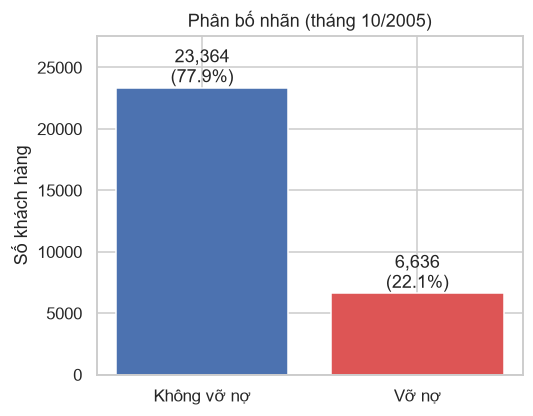

In [6]:
counts = df["Lớp"].value_counts().reindex(CLASS_NAMES.values())
fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(counts.index, counts.values, color=[PALETTE[c] for c in counts.index])
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,}\n({v / len(df):.1%})", ha="center", va="bottom")
ax.set_ylim(0, counts.max() * 1.18)
ax.set_ylabel("Số khách hàng")
ax.set_title("Phân bố nhãn (tháng 10/2005)")
plt.show()

Tỷ lệ vỡ nợ là 22,12%. Một bộ phân loại luôn dự đoán "không vỡ nợ" vẫn đạt độ chính xác 77,88%, vì vậy accuracy không được dùng làm độ đo chính.

### 2.2. Thống kê mô tả

In [7]:
desc = feats.describe().T
desc["skew"] = feats.skew()
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,skew
LIMIT_BAL,30000.0,167484.32,129747.66,10000.0,50000.00,140000.0,240000.00,1000000.0,0.99
SEX,30000.0,1.60,0.49,1.0,1.00,2.0,2.00,2.0,-0.42
EDUCATION,30000.0,1.85,0.79,0.0,1.00,2.0,2.00,6.0,0.97
MARRIAGE,30000.0,1.55,0.52,0.0,1.00,2.0,2.00,3.0,-0.02
AGE,30000.0,35.49,9.22,21.0,28.00,34.0,41.00,79.0,0.73
PAY_0,30000.0,-0.02,1.12,-2.0,-1.00,0.0,0.00,8.0,0.73
PAY_2,30000.0,-0.13,1.20,-2.0,-1.00,0.0,0.00,8.0,0.79
PAY_3,30000.0,-0.17,1.20,-2.0,-1.00,0.0,0.00,8.0,0.84
PAY_4,30000.0,-0.22,1.17,-2.0,-1.00,0.0,0.00,8.0,1.00
PAY_5,30000.0,-0.27,1.13,-2.0,-1.00,0.0,0.00,8.0,1.01


Các đặc trưng tiền tệ lệch phải mạnh. Ở phần tiền xử lý sẽ thử biến đổi log và chuẩn hóa cho mô hình tuyến tính; dư nợ âm cần phép log có dấu.


## 3. Lịch sử trả nợ

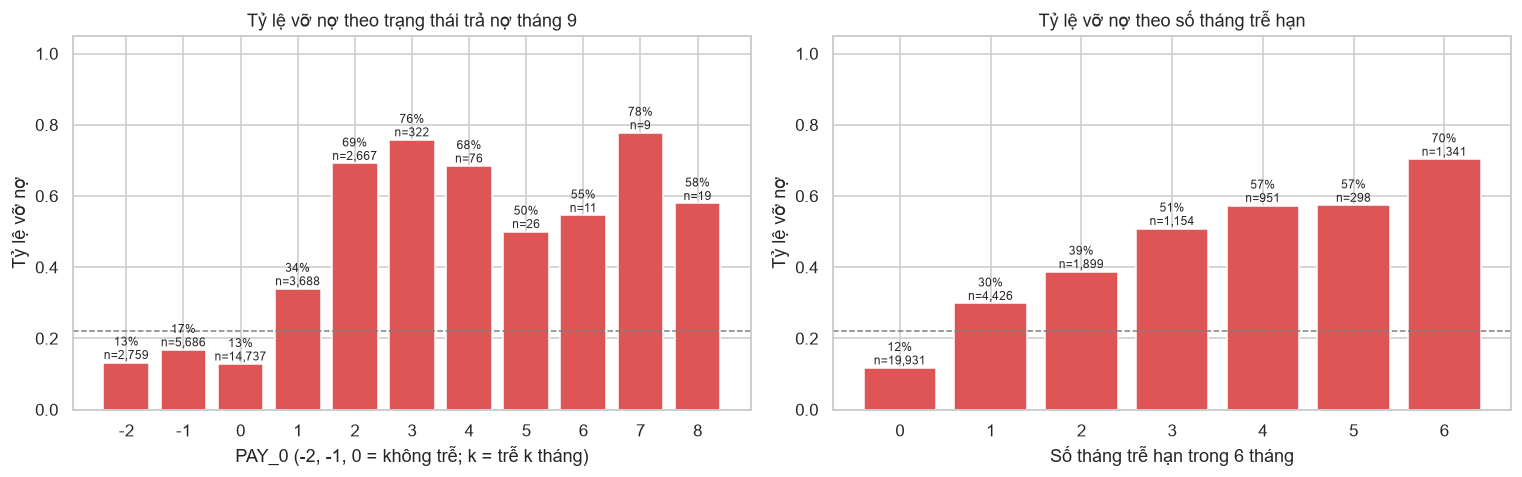

,0,1,2,3,4,5,6
Số khách,19931.000,4426.000,1899.000,1154.000,951.000,298.000,1341.000
Tỷ lệ vỡ nợ,0.117,0.298,0.388,0.509,0.573,0.574,0.703


In [8]:
rate = df.groupby("PAY_0")[TARGET].agg(["count", "mean"])
late = (df[PAY] > 0).sum(axis=1)
g = df.groupby(late)[TARGET].agg(["count", "mean"])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, tab, xlabel, title in [
    (axes[0], rate, "PAY_0 (-2, -1, 0 = không trễ; k = trễ k tháng)", "Tỷ lệ vỡ nợ theo trạng thái trả nợ tháng 9"),
    (axes[1], g, "Số tháng trễ hạn trong 6 tháng", "Tỷ lệ vỡ nợ theo số tháng trễ hạn"),
]:
    ax.bar(tab.index.astype(str), tab["mean"], color="#DD5555")
    for i, (n, r) in enumerate(zip(tab["count"], tab["mean"])):
        ax.text(i, r, f"{r:.0%}\nn={n:,}", ha="center", va="bottom", fontsize=8)
    ax.axhline(df[TARGET].mean(), ls="--", c="gray", lw=1)
    ax.set_ylim(0, 1.05)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Tỷ lệ vỡ nợ")
    ax.set_title(title)
plt.tight_layout()
plt.show()
g.rename(columns={"count": "Số khách", "mean": "Tỷ lệ vỡ nợ"}).T.round(3)

Khách hàng không trễ hạn ở tháng 9 có tỷ lệ vỡ nợ 13–17%, trong khi khách trễ 2 tháng có tỷ lệ 69%. Tỷ lệ vỡ nợ tăng gần như đơn điệu theo số tháng trễ hạn, từ 11,7% lên 70,3%.

## 4. Diễn biến hành vi qua sáu tháng

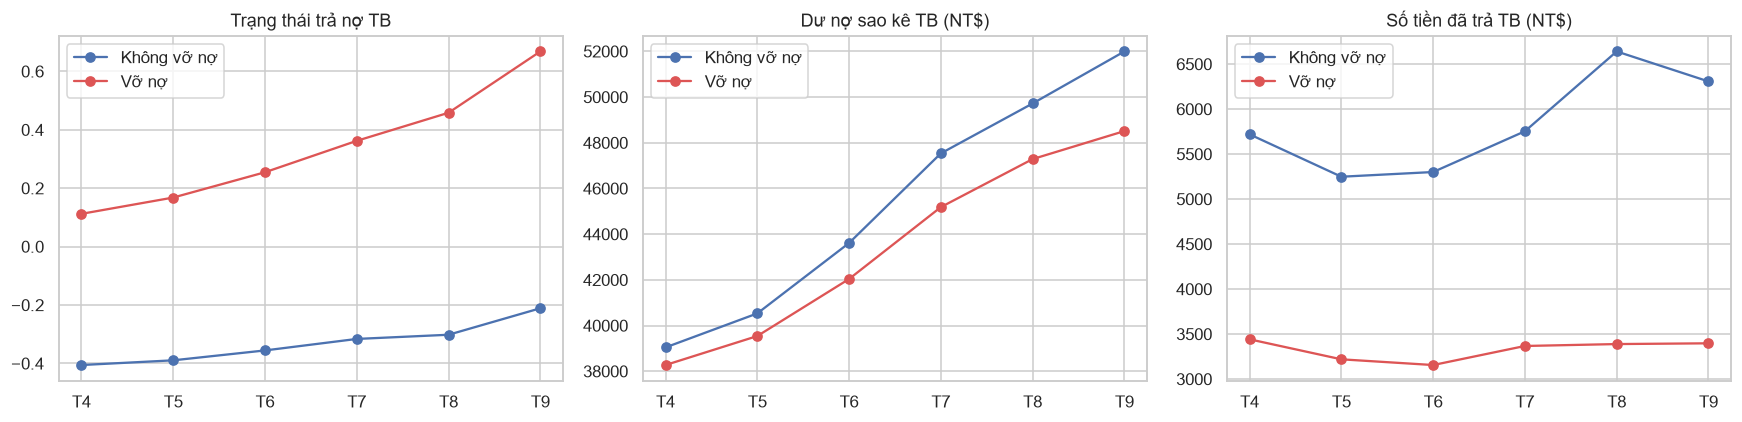

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, cols, title in [(axes[0], PAY, "Trạng thái trả nợ TB"),
                        (axes[1], BILL, "Dư nợ sao kê TB (NT$)"),
                        (axes[2], PAYAMT, "Số tiền đã trả TB (NT$)")]:
    m = df.groupby("Lớp")[cols].mean()
    for cls, row in m.iterrows():
        ax.plot(MONTHS[::-1], row.values[::-1], marker="o", label=cls, color=PALETTE[cls])
    ax.set_title(title)
    ax.legend()
plt.tight_layout()
plt.show()

Trạng thái trả nợ của nhóm vỡ nợ xấu đi liên tục từ tháng 4 đến tháng 9, còn nhóm không vỡ nợ gần như ổn định. Dư nợ của hai nhóm gần như song song; khác biệt lớn nằm ở số tiền thanh toán (khoảng 3.200–3.400 NT$ so với 5.200–6.600 NT$ mỗi tháng).

## 5. Hạn mức tín dụng và tuổi

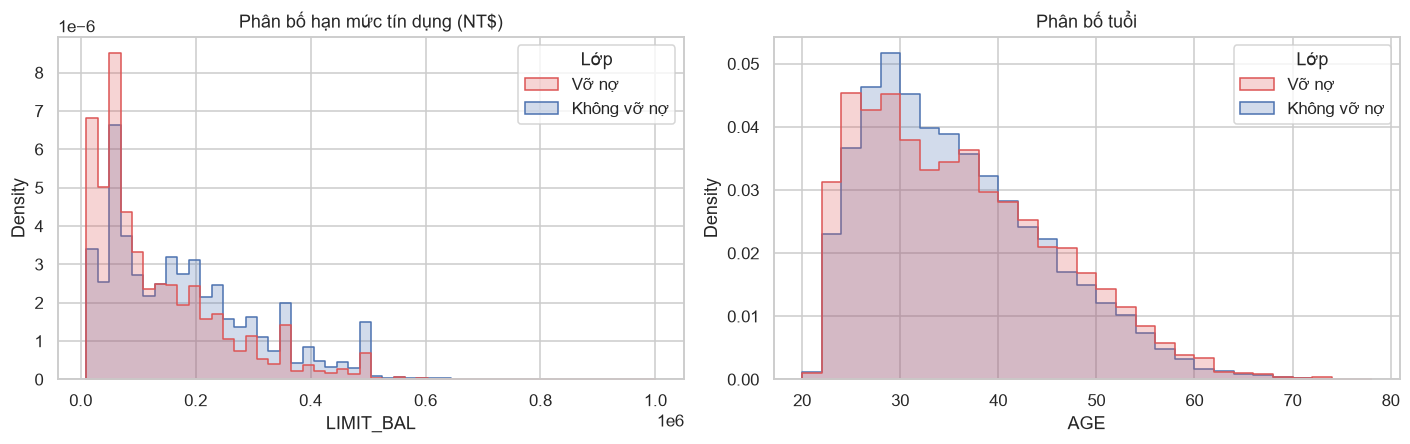

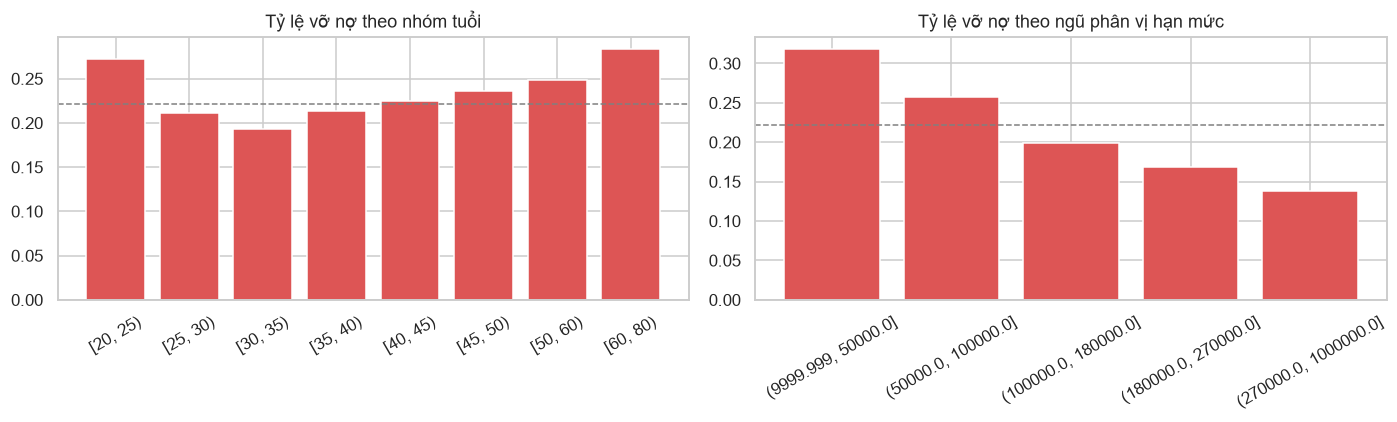

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
sns.histplot(data=df, x="LIMIT_BAL", hue="Lớp", stat="density", common_norm=False,
             bins=50, element="step", palette=PALETTE, ax=axes[0])
axes[0].set_title("Phân bố hạn mức tín dụng (NT$)")
sns.histplot(data=df, x="AGE", hue="Lớp", stat="density", common_norm=False,
             bins=range(20, 80, 2), element="step", palette=PALETTE, ax=axes[1])
axes[1].set_title("Phân bố tuổi")
plt.tight_layout()
plt.show()

age_bin = pd.cut(df["AGE"], [20, 25, 30, 35, 40, 45, 50, 60, 80], right=False)
lim_bin = pd.qcut(df["LIMIT_BAL"], 5)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, b, title in [(axes[0], age_bin, "nhóm tuổi"), (axes[1], lim_bin, "ngũ phân vị hạn mức")]:
    r = df.groupby(b, observed=True)[TARGET].mean()
    ax.bar(r.index.astype(str), r.values, color="#DD5555")
    ax.axhline(df[TARGET].mean(), ls="--", c="gray", lw=1)
    ax.set_title(f"Tỷ lệ vỡ nợ theo {title}")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

In [11]:
rows = []
for col in ["LIMIT_BAL", "AGE"] + BILL + PAYAMT:
    a, b = df.loc[df[TARGET] == 0, col], df.loc[df[TARGET] == 1, col]
    rows.append({"Đặc trưng": col, "Trung vị (không vỡ nợ)": a.median(),
                 "Trung vị (vỡ nợ)": b.median(), "p-value Mann–Whitney": stats.mannwhitneyu(a, b).pvalue})
pd.DataFrame(rows)

,Đặc trưng,Trung vị (không vỡ nợ),Trung vị (vỡ nợ),p-value Mann–Whitney
0,LIMIT_BAL,150000.0,90000.0,1.225549e-189
1,AGE,34.0,34.0,3.725035e-01
2,BILL_AMT1,23119.5,20185.0,1.151038e-05
3,BILL_AMT2,21660.5,20300.5,7.061205e-03
4,BILL_AMT3,20202.5,19834.5,2.820270e-02
5,BILL_AMT4,19000.0,19119.5,1.477678e-01
6,BILL_AMT5,17998.0,18478.5,2.353670e-01
7,BILL_AMT6,16679.0,18028.5,9.894808e-01
8,PAY_AMT1,2459.5,1636.0,4.616659e-170
9,PAY_AMT2,2247.5,1533.5,9.954976e-151


Hạn mức càng thấp thì rủi ro càng cao (31,8% ở nhóm thấp nhất so với 13,8% ở nhóm cao nhất). Tuổi có quan hệ hình chữ U: rủi ro cao ở nhóm 20–24 và từ 60 tuổi, thấp nhất ở 30–34, trong khi trung vị tuổi hai lớp bằng nhau (p = 0,37). Đây là quan hệ phi tuyến mà mô hình tuyến tính khó nắm bắt.

## 6. Các đặc trưng nhân khẩu học

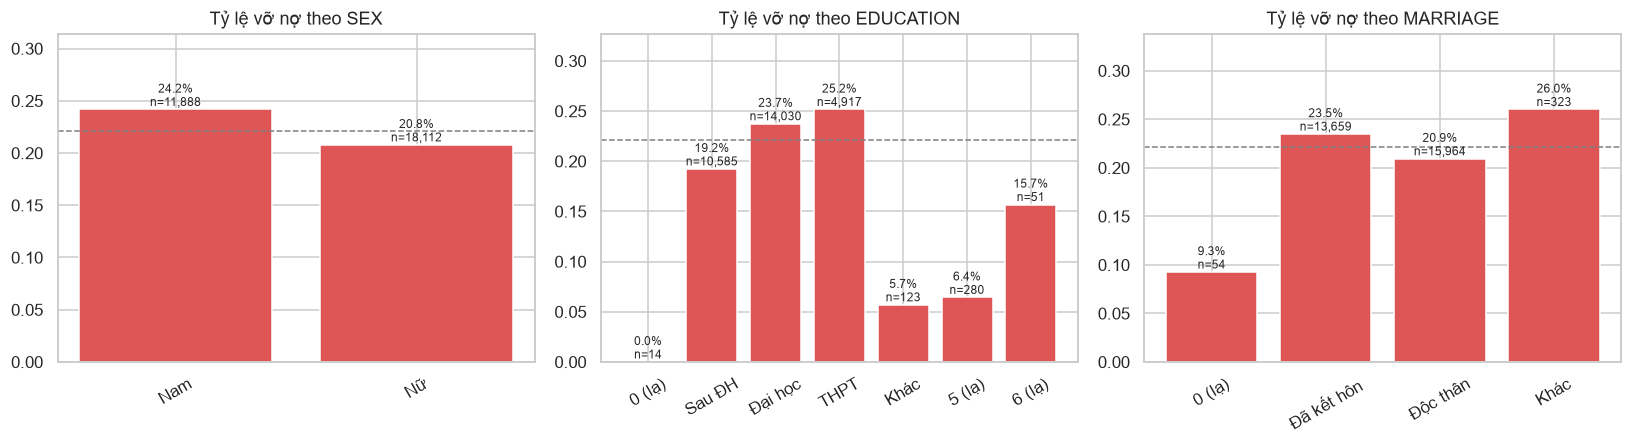

,Đặc trưng,chi2,p-value
0,SEX,47.71,4.944679e-12
1,EDUCATION,163.22,1.233263e-32
2,MARRIAGE,35.66,8.825862e-08


In [12]:
labels = {
    "SEX": {1: "Nam", 2: "Nữ"},
    "EDUCATION": {0: "0 (lạ)", 1: "Sau ĐH", 2: "Đại học", 3: "THPT", 4: "Khác", 5: "5 (lạ)", 6: "6 (lạ)"},
    "MARRIAGE": {0: "0 (lạ)", 1: "Đã kết hôn", 2: "Độc thân", 3: "Khác"},
}
chi_rows = []
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (col, mp) in zip(axes, labels.items()):
    r = df.groupby(col)[TARGET].agg(["count", "mean"]).rename(index=mp)
    ax.bar(r.index.astype(str), r["mean"], color="#DD5555")
    for i, (n, v) in enumerate(zip(r["count"], r["mean"])):
        ax.text(i, v, f"{v:.1%}\nn={n:,}", ha="center", va="bottom", fontsize=8)
    ax.axhline(df[TARGET].mean(), ls="--", c="gray", lw=1)
    ax.set_ylim(0, r["mean"].max() * 1.3)
    ax.set_title(f"Tỷ lệ vỡ nợ theo {col}")
    ax.tick_params(axis="x", rotation=30)
    chi2, p, *_ = stats.chi2_contingency(pd.crosstab(df[col], df[TARGET]))
    chi_rows.append({"Đặc trưng": col, "chi2": round(chi2, 2), "p-value": p})
plt.tight_layout()
plt.show()
pd.DataFrame(chi_rows)

Cả ba đặc trưng đều có liên hệ có ý nghĩa thống kê với nhãn, nhưng mức chênh lệch chỉ vài điểm phần trăm. Với cỡ mẫu lớn, p-value rất nhỏ ngay cả khi hiệu ứng yếu. Việc dùng các đặc trưng này cho quyết định tín dụng cũng đặt ra vấn đề công bằng.

## 7. Phân tích tương quan (Spearman)

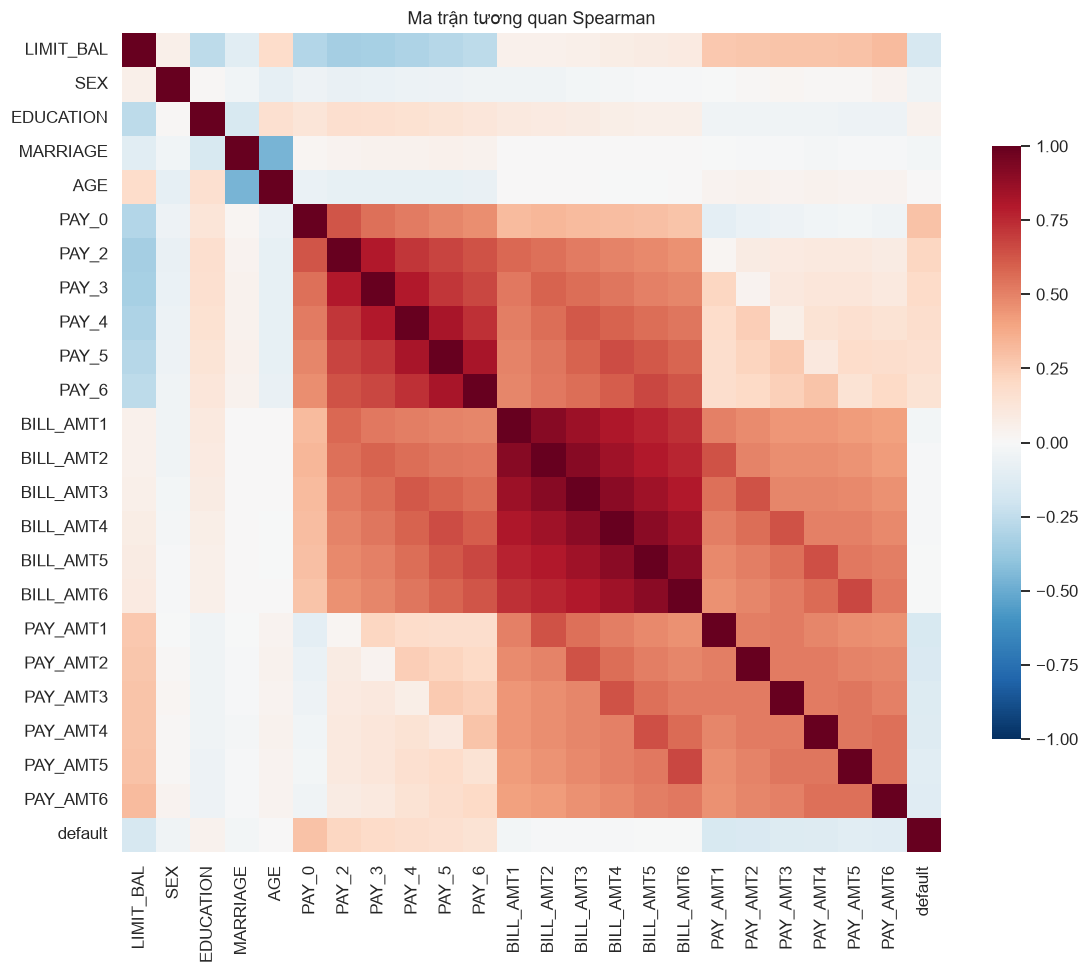

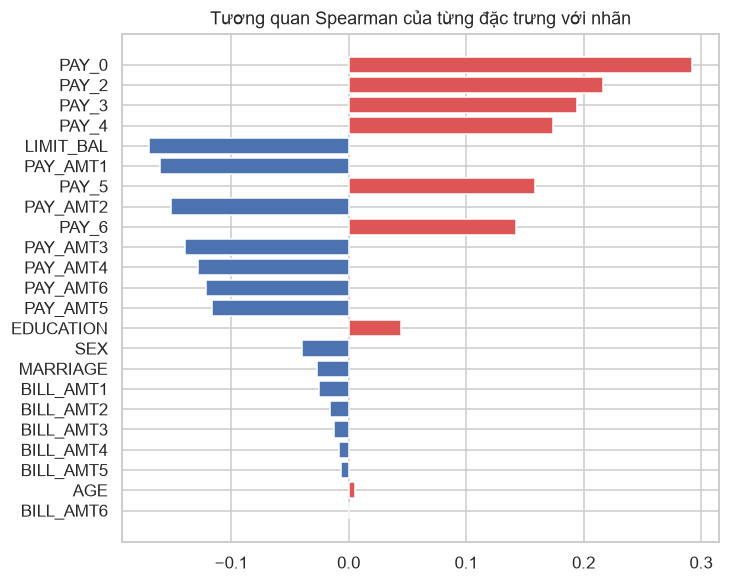

,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6
BILL_AMT1,1.000,0.911,0.858,0.807,0.769,0.734
BILL_AMT2,0.911,1.000,0.908,0.848,0.803,0.765
BILL_AMT3,0.858,0.908,1.000,0.904,0.849,0.804
BILL_AMT4,0.807,0.848,0.904,1.000,0.903,0.848
BILL_AMT5,0.769,0.803,0.849,0.903,1.000,0.902
BILL_AMT6,0.734,0.765,0.804,0.848,0.902,1.000


In [13]:
corr = df.drop(columns=["ID", "Lớp"]).corr(method="spearman")
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True, cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Ma trận tương quan Spearman")
plt.show()

with_target = corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(with_target.index[::-1], with_target.values[::-1],
        color=["#DD5555" if v > 0 else "#4C72B0" for v in with_target.values[::-1]])
ax.set_title("Tương quan Spearman của từng đặc trưng với nhãn")
plt.show()
corr.loc[BILL, BILL].round(3)

Không đặc trưng đơn lẻ nào tương quan mạnh với nhãn (cao nhất là `PAY_0` với ρ = 0,29). Nhóm `BILL_AMT` có đa cộng tuyến mạnh (0,73–0,91) nhưng gần như không tương quan với nhãn.

## 8. Mức độ chồng lấn giữa hai lớp (PCA và Fisher LDA)

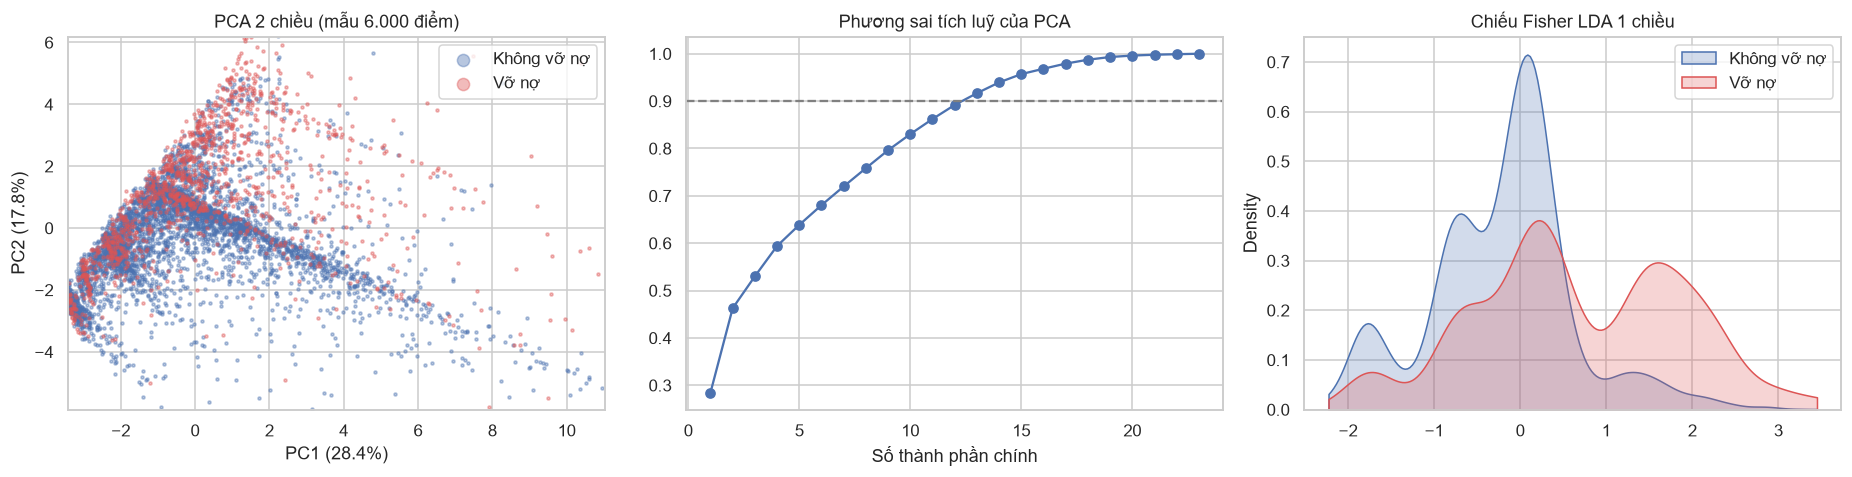

Số thành phần chính đạt 90% phương sai: 13


In [14]:
X = StandardScaler().fit_transform(feats)
y = df[TARGET].values
pca = PCA().fit(X)
Z = pca.transform(X)[:, :2]
z_lda = LinearDiscriminantAnalysis(n_components=1).fit(X, y).transform(X).ravel()

idx = np.random.default_rng(42).choice(len(df), 6000, replace=False)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for cls in (0, 1):
    m = y[idx] == cls
    axes[0].scatter(Z[idx][m, 0], Z[idx][m, 1], s=4, alpha=0.4, color=PALETTE[CLASS_NAMES[cls]], label=CLASS_NAMES[cls])
axes[0].set_xlim(np.percentile(Z[:, 0], [0.5, 99.5]))
axes[0].set_ylim(np.percentile(Z[:, 1], [0.5, 99.5]))
axes[0].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
axes[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
axes[0].set_title("PCA 2 chiều (mẫu 6.000 điểm)")
axes[0].legend(markerscale=4)

cum = np.cumsum(pca.explained_variance_ratio_)
axes[1].plot(range(1, len(cum) + 1), cum, marker="o")
axes[1].axhline(0.9, ls="--", c="gray")
axes[1].set_xlabel("Số thành phần chính")
axes[1].set_title("Phương sai tích luỹ của PCA")

for cls in (0, 1):
    sns.kdeplot(z_lda[y == cls], ax=axes[2], fill=True, color=PALETTE[CLASS_NAMES[cls]],
                label=CLASS_NAMES[cls], clip=np.percentile(z_lda, [0.5, 99.5]))
axes[2].set_title("Chiếu Fisher LDA 1 chiều")
axes[2].legend()
plt.tight_layout()
plt.show()
print("Số thành phần chính đạt 90% phương sai:", int(np.argmax(cum >= 0.9) + 1))

Hai lớp chồng lấn nhiều trên các phép chiếu. Điều này gợi ý việc phân loại
không đơn giản, nhưng riêng hình PCA/LDA không đủ để kết luận sai số Bayes hay
khả năng tách trong không gian đầy đủ. PCA/LDA ở đây chỉ phục vụ EDA, không được
tái sử dụng để biến đổi tập huấn luyện hoặc kiểm tra ở phần sau.


## 9. Đặc trưng phái sinh: tỷ lệ sử dụng hạn mức

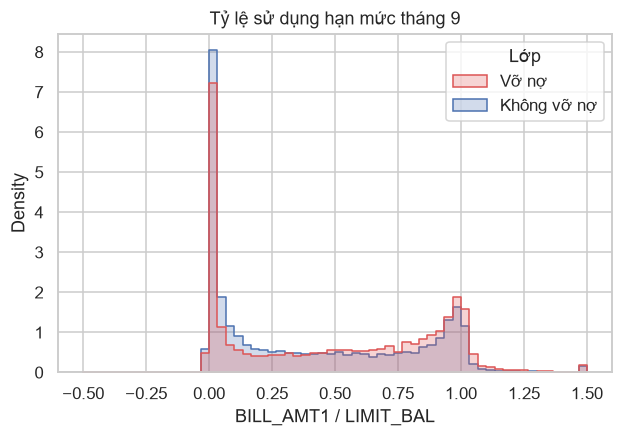

,"(-0.5, 0.0]","(0.0, 0.25]","(0.25, 0.5]","(0.5, 0.75]","(0.75, 1.0]","(1.0, 1.5]"
count,2596.000,11440.000,3588.000,3579.00,6680.000,2115.000
mean,0.248,0.168,0.217,0.26,0.258,0.301


In [15]:
util = (df["BILL_AMT1"] / df["LIMIT_BAL"]).clip(-0.5, 1.5)
fig, ax = plt.subplots(figsize=(6.5, 4))
sns.histplot(x=util, hue=df["Lớp"], stat="density", common_norm=False, bins=60,
             element="step", palette=PALETTE, ax=ax)
ax.set_xlabel("BILL_AMT1 / LIMIT_BAL")
ax.set_title("Tỷ lệ sử dụng hạn mức tháng 9")
plt.show()
df.groupby(pd.cut(util, [-0.5, 0, 0.25, 0.5, 0.75, 1.0, 1.5]), observed=True)[TARGET].agg(["count", "mean"]).T.round(3)

Khác với dư nợ gốc, tỷ lệ sử dụng hạn mức cho thấy xu hướng rõ: dùng càng gần hết hạn mức thì rủi ro càng cao (16,8% ở mức dưới 25% so với 30,1% khi vượt hạn mức).

## 10. Tổng kết và định hướng

| Phát hiện | Định hướng |
|---|---|
| Mất cân bằng lớp (22% vỡ nợ) | ROC-AUC, PR-AUC, Recall, F1; chia có phân tầng; trọng số lớp hoặc SMOTE |
| Lịch sử trả nợ là nhóm mạnh nhất | Thêm số tháng trễ, mức trễ lớn nhất, xu hướng trễ |
| `BILL_AMT` đa cộng tuyến, ít thông tin | Tỷ lệ sử dụng hạn mức, tỷ lệ thanh toán, hoặc PCA |
| `PAY_AMT` lệch mạnh | Biến đổi log(1 + x) |
| Tuổi có quan hệ hình chữ U | Mô hình dạng cây/boosting hoặc chia nhóm tuổi |
| Mã lạ ở `EDUCATION`, `MARRIAGE` | Gộp vào nhóm "Khác" |
| Hai lớp chồng lấn nhiều | Chọn ngưỡng theo quy tắc rủi ro tối thiểu Bayes |

# Phần 2. Tiền xử lý dữ liệu

Tiếp tục từ `raw_df`, không lấy các cột hay phép chiếu đã tạo trong EDA.
Quy tắc làm sạch và pipeline tương ứng với `src/preprocessing.py`.
EDA đã xem toàn bộ dữ liệu; cần ghi nhận điều này trong báo cáo. Các thống kê
chuẩn hóa bên dưới chỉ học trên train, không dùng validation/test.

## 11. Khai báo cấu hình


In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

CATEGORICAL = ['SEX', 'EDUCATION', 'MARRIAGE']
PAYMENT = PAYAMT.copy()
FEATURES = ['LIMIT_BAL', *CATEGORICAL, 'AGE', *PAY, *BILL, *PAYMENT]
DERIVED = ['late_month_count', 'max_delay', 'recent_delay_change',
           'utilization_sep', 'mean_payment', 'zero_payment_count']
SEED = 42


## 12. Kiểm tra và làm sạch

Kiểm tra cột, nhãn, ID, mã phân loại và số hữu hạn; loại bản sao hoàn toàn khi
bỏ ID. Gộp EDUCATION 0/5/6 về 4, MARRIAGE 0 về 3. Giữ dư nợ âm, PAY âm/0 và
các khoản tiền lớn. Không cần điền thiếu với dữ liệu gốc hiện có.

Các hồ sơ cùng đặc trưng nhưng khác nhãn vẫn được giữ và gom cùng nhóm để chia tập.


In [17]:
def clean_data(raw):
    """Quy tắc cố định, không ước lượng thống kê từ dữ liệu."""
    df = raw.rename(columns={'default payment next month': TARGET}).copy()
    expected = ['ID', *FEATURES, TARGET]
    if set(df.columns) != set(expected):
        raise ValueError('Cấu trúc cột không đúng với dữ liệu UCI gốc.')
    df = df[expected].apply(pd.to_numeric, errors='raise')
    if not np.isfinite(df.to_numpy()).all():
        raise ValueError('Dữ liệu chứa giá trị thiếu hoặc vô cực; cần kiểm tra nguồn.')
    if not df[TARGET].isin([0, 1]).all() or not df.ID.is_unique:
        raise ValueError('Nhãn phải là 0/1 và ID phải duy nhất.')
    if (df.LIMIT_BAL <= 0).any() or (df[PAYMENT] < 0).any().any():
        raise ValueError('Hạn mức phải dương, số tiền thanh toán không được âm.')
    for col, valid in {'SEX': [1, 2], 'EDUCATION': list(range(7)),
                       'MARRIAGE': list(range(4)), **{p: list(range(-2, 10)) for p in PAY}}.items():
        if not df[col].isin(valid).all():
            raise ValueError(f'Mã ngoài miền dự kiến: {col}')
    duplicate = df.duplicated(subset=[*FEATURES, TARGET])
    removed_ids = df.loc[duplicate, ['ID']].copy()
    audit = {'raw_rows': len(df), 'missing_values': int(df.isna().sum().sum()),
             'exact_duplicates_removed': int(duplicate.sum())}
    df = df.loc[~duplicate].copy()
    audit['education_remapped'] = int(df.EDUCATION.isin([0, 5, 6]).sum())
    audit['marriage_remapped'] = int(df.MARRIAGE.eq(0).sum())
    df['EDUCATION'] = df.EDUCATION.replace({0: 4, 5: 4, 6: 4})
    df['MARRIAGE'] = df.MARRIAGE.replace({0: 3})
    df[TARGET] = df[TARGET].astype(int)
    df = df.reset_index(drop=True)
    # Giữ cả nhãn mâu thuẫn; gom hồ sơ giống nhau vào cùng tập sau khi gộp mã.
    groups = df.groupby(FEATURES, sort=True, dropna=False).ngroup()
    audit['clean_rows'] = len(df)
    audit['identical_feature_groups'] = int(groups.value_counts().gt(1).sum())
    audit['conflicting_label_groups'] = int(df.groupby(groups)[TARGET].nunique().gt(1).sum())
    return df, groups, audit, removed_ids


In [18]:
clean_df, groups, audit, removed_ids = clean_data(raw_df)
display(pd.Series(audit, name='Giá trị').to_frame())
display(removed_ids.head())
display(clean_df.head())


,Giá trị
raw_rows,30000
missing_values,0
exact_duplicates_removed,35
education_remapped,345
marriage_remapped,54
clean_rows,29965
identical_feature_groups,21
conflicting_label_groups,21


,ID
1980,1981
4585,4586
6022,6023
6466,6467
7319,7320


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
0,1,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0


## 13. Chia train / validation / test

Chia 20 folds phân tầng theo nhóm với seed 42, gộp 14/3/3 folds để đạt xấp xỉ
70%/15%/15%. Ràng buộc nhóm khiến tỷ lệ có thể lệch nhẹ. `manifest` lưu ID và
nhóm để có thể dùng lại khi cross-validation. Đây là chia theo khách hàng,
không phải kiểm tra dự đoán trên một giai đoạn thời gian mới.


In [19]:
def split_data(df, groups):
    """20 folds phân tầng theo nhóm: 14 train, 3 validation, 3 test (~70/15/15)."""
    folds = np.full(len(df), -1)
    splitter = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=SEED)
    for fold, (_, indices) in enumerate(splitter.split(df[FEATURES], df[TARGET], groups)):
        folds[indices] = fold
    names = np.where(folds < 14, 'train', np.where(folds < 17, 'validation', 'test'))
    manifest = pd.DataFrame({'ID': df.ID, 'group_id': groups, 'fold': folds, 'split': names})
    if manifest.groupby('group_id')['split'].nunique().max() != 1:
        raise AssertionError('Hồ sơ giống nhau xuất hiện ở nhiều tập.')
    parts = {name: df.loc[names == name].copy() for name in ['train', 'validation', 'test']}
    for part in parts.values():
        if part[TARGET].nunique() != 2:
            raise ValueError('Mỗi tập phải có đủ hai lớp.')
    return parts, manifest


In [20]:
parts, manifest = split_data(clean_df, groups)
split_summary = pd.DataFrame([
    {'Tập': name, 'Số mẫu': len(part), 'Tỷ lệ mẫu': len(part) / len(clean_df),
     'Số vỡ nợ': int(part[TARGET].sum()), 'Tỷ lệ vỡ nợ': part[TARGET].mean()}
    for name, part in parts.items()
])
display(split_summary)
X_splits = {name: part[FEATURES].copy() for name, part in parts.items()}
y_splits = {name: part[TARGET].copy() for name, part in parts.items()}


,Tập,Số mẫu,Tỷ lệ mẫu,Số vỡ nợ,Tỷ lệ vỡ nợ
0,train,20977,0.700050,4640,0.221195
1,validation,4494,0.149975,995,0.221406
2,test,4494,0.149975,995,0.221406


## 14. Tạo sáu đặc trưng hành vi

Số tháng trễ, mức trễ lớn nhất, thay đổi trạng thái gần nhất, mức sử dụng hạn
mức tháng 9, tiền thanh toán trung bình và số tháng không thanh toán. Tính
riêng từng khách hàng; không dùng nhãn hay thống kê toàn bộ dữ liệu.


In [21]:
def add_features(X):
    X = X.copy()
    X['late_month_count'] = X[PAY].gt(0).sum(axis=1)
    X['max_delay'] = X[PAY].max(axis=1).clip(lower=0)
    X['recent_delay_change'] = X.PAY_0 - X.PAY_2
    X['utilization_sep'] = X.BILL_AMT1 / X.LIMIT_BAL
    X['mean_payment'] = X[PAYMENT].mean(axis=1)
    X['zero_payment_count'] = X[PAYMENT].eq(0).sum(axis=1)
    return X

display(add_features(X_splits["train"])[DERIVED].head())


,late_month_count,max_delay,recent_delay_change,utilization_sep,mean_payment,zero_payment_count
0,2,2,0,0.195650,114.833333,5
1,2,2,-3,0.022350,833.333333,2
2,0,0,0,0.324878,1836.333333,0
3,0,0,0,0.939800,1398.000000,0
4,0,0,-1,0.172340,9841.500000,0


## 15. Xây dựng pipeline chưa fit

- `linear`: log1p cho hạn mức/tiền thanh toán; log có dấu cho dư nợ; chuẩn hóa cột số.
- `tree`: giữ nguyên các cột số.
- Cả hai one-hot SEX/EDUCATION/MARRIAGE, bỏ nhóm tham chiếu đầu tiên.
- `base`: đặc trưng gốc; `extended`: thêm sáu đặc trưng hành vi.

Không sử dụng PCA hoặc SMOTE mặc định. Các cấu hình cần được so sánh trong
bước mô hình hóa; không mặc định rằng log luôn cải thiện kết quả.


In [22]:
def signed_log1p(X):
    return np.sign(X) * np.log1p(np.abs(X))

def make_preprocessor(kind='linear', with_features=False):
    """Trả về pipeline CHƯA fit; ghép với mô hình trước khi cross-validation."""
    if kind not in ('linear', 'tree'):
        raise ValueError('kind phải là linear hoặc tree')
    numeric = [c for c in FEATURES if c not in CATEGORICAL]
    if with_features:
        numeric += DERIVED
    cat = OneHotEncoder(categories=[[1, 2], [1, 2, 3, 4], [1, 2, 3]],
                        drop='first', handle_unknown='error', sparse_output=False)
    if kind == 'linear':
        positive = ['LIMIT_BAL', *PAYMENT] + (['mean_payment'] if with_features else [])
        other = [c for c in numeric if c not in positive + BILL]
        transforms = [
            ('positive', Pipeline([('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
                                   ('scale', StandardScaler())]), positive),
            ('bills', Pipeline([('log', FunctionTransformer(signed_log1p, feature_names_out='one-to-one')),
                                ('scale', StandardScaler())]), BILL),
            ('numeric', StandardScaler(), other), ('category', cat, CATEGORICAL)]
    else:
        transforms = [('numeric', 'passthrough', numeric), ('category', cat, CATEGORICAL)]
    steps = []
    if with_features:
        steps.append(('features', FunctionTransformer(add_features)))
    steps.append(('columns', ColumnTransformer(transforms, remainder='drop', verbose_feature_names_out=True)))
    return Pipeline(steps)


## 16. Fit trên train và biến đổi ba tập

`prepared` chứa bốn cấu hình với DataFrame X đã biến đổi. `y_splits` chứa nhãn
riêng; các DataFrame X không có ID/default. ID được giữ làm chỉ mục để đối chiếu.
Không có file nào được ghi ra đĩa.


In [23]:
preprocessors = {}
prepared = {}
for kind in ['linear', 'tree']:
    for extended in [False, True]:
        key = kind + ('_extended' if extended else '_base')
        preprocessor = make_preprocessor(kind, with_features=extended)
        preprocessor.fit(X_splits['train'])
        names = preprocessor.named_steps['columns'].get_feature_names_out()
        prepared[key] = {}
        for split, X_part in X_splits.items():
            prepared[key][split] = pd.DataFrame(
                preprocessor.transform(X_part), columns=names,
                index=pd.Index(parts[split]['ID'].to_numpy(), name='ID'),
            )
        preprocessors[key] = preprocessor

# Đặt nhãn theo cùng chỉ mục ID để tránh pandas ghép sai dòng.
y_splits = {
    split: pd.Series(part[TARGET].to_numpy(),
                     index=pd.Index(part['ID'].to_numpy(), name='ID'), name=TARGET)
    for split, part in parts.items()
}
display(pd.DataFrame([
    {'Cấu hình': key, 'Số đặc trưng': frames['train'].shape[1],
     'Train': len(frames['train']), 'Validation': len(frames['validation']),
     'Test': len(frames['test'])}
    for key, frames in prepared.items()
]))
display(prepared['linear_extended']['train'].head())


,Cấu hình,Số đặc trưng,Train,Validation,Test
0,linear_base,26,20977,4494,4494
1,linear_extended,32,20977,4494,4494
2,tree_base,26,20977,4494,4494
3,tree_extended,32,20977,4494,4494


,positive__LIMIT_BAL,positive__PAY_AMT1,positive__PAY_AMT2,positive__PAY_AMT3,positive__PAY_AMT4,positive__PAY_AMT5,positive__PAY_AMT6,positive__mean_payment,bills__BILL_AMT1,bills__BILL_AMT2,bills__BILL_AMT3,bills__BILL_AMT4,bills__BILL_AMT5,bills__BILL_AMT6,numeric__AGE,...,numeric__PAY_3,numeric__PAY_4,numeric__PAY_5,numeric__PAY_6,numeric__late_month_count,numeric__max_delay,numeric__recent_delay_change,numeric__utilization_sep,numeric__zero_payment_count,category__SEX_2,category__EDUCATION_2,category__EDUCATION_3,category__EDUCATION_4,category__MARRIAGE_2,category__MARRIAGE_3
ID,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,-1.870380,-2.052646,-0.019114,-1.888383,-1.799843,-1.759365,-1.687560,-1.365056,-0.198632,-0.191602,-0.543668,-2.140497,-2.051133,-1.915294,-1.243155,...,-0.697957,-0.670113,-1.531672,-1.481962,0.747610,1.225321,-0.121899,-0.555737,2.215376,1.0,1.0,0.0,0.0,0.0,0.0
2,0.031336,-2.052646,0.095352,0.179422,0.241925,-1.759365,0.470049,-0.394512,-0.305479,-0.346473,-0.193133,-0.099800,-0.038420,0.001219,-1.026388,...,0.137958,0.182186,0.226798,1.980337,0.747610,1.225321,-3.335650,-0.977129,0.459067,1.0,1.0,0.0,0.0,1.0,0.0
3,-0.274004,0.209948,0.219992,0.179422,0.241925,0.252076,0.730047,-0.006468,0.370364,0.206739,0.225080,0.272559,0.323354,0.371184,-0.159318,...,0.137958,0.182186,0.226798,0.249188,-0.535484,-0.633215,-0.121899,-0.241511,-0.711806,1.0,1.0,0.0,0.0,1.0,0.0
4,-0.897867,0.295066,0.311354,0.233941,0.270065,0.271483,0.273446,-0.140442,0.504598,0.532820,0.558228,0.444242,0.486703,0.523261,0.165833,...,0.137958,0.182186,0.226798,0.249188,-0.535484,-0.633215,-0.121899,1.253716,-0.711806,1.0,1.0,0.0,0.0,0.0,0.0
5,-0.897867,0.295066,1.203295,0.868321,0.891015,0.143752,0.163694,0.818536,0.024694,-0.032392,0.475935,0.368175,0.384493,0.420293,2.333508,...,-0.697957,0.182186,0.226798,0.249188,-0.535484,-0.633215,-1.193149,-0.612417,-0.711806,0.0,1.0,0.0,0.0,0.0,0.0


## 17. Kiểm tra đầu ra và tính toàn vẹn

Kiểm tra các tập không giao ID/nhóm, bao phủ toàn bộ dữ liệu sạch, không có
NaN/vô cực, cột thống nhất và nhãn khớp chỉ mục của X.


In [24]:
assert manifest.ID.is_unique
assert set(manifest.ID) == set(clean_df.ID)
assert manifest.groupby('group_id')['split'].nunique().max() == 1
assert sum(len(part) for part in parts.values()) == len(clean_df)
for key, frames in prepared.items():
    for split, X_part in frames.items():
        assert np.isfinite(X_part.to_numpy()).all(), (key, split)
        assert X_part.columns.equals(frames['train'].columns)
        assert X_part.index.equals(y_splits[split].index)
        assert not any(c.endswith('__ID') or c.endswith('__default') for c in X_part.columns)
print('Các kiểm tra đều đạt. Dữ liệu được giữ trong bộ nhớ, không ghi file.')


Các kiểm tra đều đạt. Dữ liệu được giữ trong bộ nhớ, không ghi file.


## 18. Bàn giao cho bước huấn luyện

Ví dụ chọn bản `linear_extended` bên dưới. Chưa huấn luyện mô hình trong notebook
này. Validation dùng chọn cấu hình/ngưỡng; test để đánh giá cuối cùng.

Nếu cross-validation: dùng `X_splits['train']` (chưa biến đổi), nhãn từ
`parts['train'][TARGET]` và pipeline mới từ `make_preprocessor`, ghép với bộ phân
loại. Dùng nhóm từ manifest căn theo ID và StratifiedGroupKFold trong train.
**Không đưa X đã chuẩn hóa trên toàn train vào cross-validation**, vì mỗi fold
cần học lại các tham số chuẩn hóa. Giữ phân bố nhãn; trọng số lớp hoặc lấy mẫu
lại là thí nghiệm ở bước huấn luyện.


In [25]:
selected = 'linear_extended'
X_train = prepared[selected]['train']
X_validation = prepared[selected]['validation']
X_test = prepared[selected]['test']
y_train = y_splits['train']
y_validation = y_splits['validation']
y_test = y_splits['test']
print(f'{selected}: X_train={X_train.shape}, y_train={y_train.shape}')


linear_extended: X_train=(20977, 32), y_train=(20977,)


# Phần 3. Xây dựng tập đánh giá

Phần này cố định cách đánh giá chung cho mọi mô hình ở phần sau: cùng tập test, cùng độ đo, cùng cách chọn ngưỡng và cùng cách so sánh.
Phần này không xây dựng mô hình phân loại; các hàm ở mục 22–24 được dùng cho phần baseline và mô hình.

## 19. Cố định tập đánh giá

Phép chia ở mục 13 có thể khác nhau giữa các phiên bản pandas / scikit-learn. Phép chia chuẩn được lưu trong `data/splits/split_manifest.csv`;
nếu tìm thấy tệp này thì dùng đúng phép chia trong đó, nếu không thì dùng `parts` của mục 13 và so số mẫu với phép chia chuẩn.

In [26]:
from sklearn.base import clone
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score, roc_curve
from sklearn.model_selection import cross_validate

COST_FN, COST_FP = 5, 1   # giả định: bỏ sót một khách vỡ nợ đắt gấp 5 lần từ chối nhầm
N_BOOT = 1000
# Số mẫu và số vỡ nợ của phép chia chuẩn
REFERENCE_SPLIT = {"train": (20976, 4608), "validation": (4493, 1001), "test": (4496, 1021)}

manifest = next((p for root in [Path("../data/splits"), Path("data/splits"), Path("/kaggle/input")]
                 if root.exists() for p in root.rglob("split_manifest.csv")), None)
if manifest is not None:
    split_of = clean_df.ID.map(pd.read_csv(manifest).set_index("ID")["split"])
    eval_parts = {name: clean_df[split_of == name] for name in ["train", "validation", "test"]}
    print("Dùng phép chia cố định từ", manifest)
else:
    eval_parts = parts
    print("Không tìm thấy split_manifest.csv; dùng phép chia của mục 13.")

X_eval = {name: part[FEATURES] for name, part in eval_parts.items()}
y_eval = {name: part[TARGET].to_numpy() for name, part in eval_parts.items()}
train_groups = groups.loc[eval_parts["train"].index].to_numpy()

split_check = pd.DataFrame([{"Tập": name, "Số mẫu": len(part), "Số vỡ nợ": int(part[TARGET].sum()),
                             "Tỷ lệ vỡ nợ": part[TARGET].mean()} for name, part in eval_parts.items()]).set_index("Tập")
display(split_check.round(4))
if any(tuple(split_check.loc[n, ["Số mẫu", "Số vỡ nợ"]]) != c for n, c in REFERENCE_SPLIT.items()):
    print("CẢNH BÁO: phép chia khác chuẩn; kết quả không so sánh được với các thành viên khác.")

Dùng phép chia cố định từ ..\data\splits\split_manifest.csv


,Số mẫu,Số vỡ nợ,Tỷ lệ vỡ nợ
Tập,,,
train,20976,4608,0.2197
validation,4493,1001,0.2228
test,4496,1021,0.2271


## 20. Phân bố của ba tập

So tỷ trọng các nhóm khách giữa train / validation / test theo bốn lát cắt dùng lại ở bước phân tích lỗi.

In [27]:
SLICES = {
    "PAY_0": lambda d: pd.cut(d.PAY_0, [-3, -1, 0, 1, 9], labels=["−2 / −1", "0", "1", "≥ 2"]),
    "Hạn mức": lambda d: pd.cut(d.LIMIT_BAL, [0, 50_000, 100_000, 180_000, 270_000, np.inf],
                                labels=["≤ 50k", "50–100k", "100–180k", "180–270k", "> 270k"]),
    "Tuổi": lambda d: pd.cut(d.AGE, [0, 29, 39, 49, 120], labels=["21–29", "30–39", "40–49", "≥ 50"]),
    "Giới tính": lambda d: d.SEX.map({1: "Nam", 2: "Nữ"}).astype(pd.CategoricalDtype(["Nam", "Nữ"])),
}

share = pd.DataFrame({name: pd.concat({s: make(part).value_counts(normalize=True, sort=False)
                                       for s, make in SLICES.items()})
                      for name, part in eval_parts.items()})
share.index.names = ["Lát cắt", "Nhóm"]
share["Lệch lớn nhất (điểm %)"] = 100 * (share.max(axis=1) - share.min(axis=1))
display(share.round(4))

train  validation    test  Lệch lớn nhất (điểm %)
Lát cắt   Nhóm                                                        
PAY_0     −2 / −1   0.2837      0.2689  0.2834                  1.4795
          0         0.4930      0.4925  0.4855                  0.7449
          1         0.1209      0.1306  0.1210                  0.9748
          ≥ 2       0.1025      0.1079  0.1101                  0.7647
Hạn mức   ≤ 50k     0.2561      0.2562  0.2556                  0.0616
          50–100k   0.1609      0.1605  0.1604                  0.0533
          100–180k  0.2039      0.2043  0.2046                  0.0774
          180–270k  0.1805      0.1807  0.1810                  0.0558
          > 270k    0.1986      0.1983  0.1984                  0.0299
Tuổi      21–29     0.3177      0.3321  0.3216                  1.4328
          30–39     0.3757      0.3724  0.3721                  0.3559
          40–49     0.2167      0.2114  0.2135                  0.5284
          ≥ 50      0.0899      0.0841  0.0927                  0.8618
Giới tính Nam       0.3970      0.3955  0.3937                  0.3294
          Nữ        0.6030      0.6045  0.6063                  0.3294

## 21. Độ đo và ngưỡng quyết định

- **PR-AUC** (độ đo chính) và ROC-AUC: không phụ thuộc ngưỡng. Accuracy không dùng để xếp hạng vì dữ liệu mất cân bằng.
- **Recall, Precision, F1** của lớp vỡ nợ tại ngưỡng đã chọn.
- **Chi phí / khách** $= (5\cdot FN + 1\cdot FP)/n$.

Theo quy tắc rủi ro tối thiểu Bayes, đoán "vỡ nợ" khi $P(\text{vỡ nợ} \mid x) > \frac{\lambda_{FP}}{\lambda_{FP} + \lambda_{FN}} = \frac{1}{6}$.
Ngưỡng này chỉ đúng khi xác suất được hiệu chỉnh tốt, nên ngưỡng được chọn trên validation: giá trị cho chi phí nhỏ nhất.

In [28]:
def evaluate(y, p, threshold):
    y, p = np.asarray(y), np.asarray(p)
    pred = p >= threshold
    tp, fp, fn = (int(np.sum(pred & (y == 1))), int(np.sum(pred & (y == 0))),
                  int(np.sum(~pred & (y == 1))))
    return {"PR-AUC": average_precision_score(y, p), "ROC-AUC": roc_auc_score(y, p),
            "Ngưỡng": threshold, "Recall": tp / max(tp + fn, 1), "Precision": tp / max(tp + fp, 1),
            "F1": 2 * tp / max(2 * tp + fp + fn, 1), "Accuracy": np.mean(pred == y),
            "Chi phí / KH": (COST_FN * fn + COST_FP * fp) / len(y), "TP": tp, "FP": fp, "FN": fn}


def min_cost_threshold(y, p):
    # Xét mọi giá trị xác suất xuất hiện và vô cực (không đoán ai vỡ nợ), chọn ngưỡng chi phí nhỏ nhất
    y, p = np.asarray(y), np.asarray(p)
    candidates = np.append(np.unique(p), np.inf)
    costs = [COST_FN * np.sum((p < t) & (y == 1)) + COST_FP * np.sum((p >= t) & (y == 0)) for t in candidates]
    return float(candidates[np.argmin(costs)])


def bootstrap(y, probs, thresholds, n_boot=N_BOOT, seed=SEED):
    # Bootstrap ghép cặp: mỗi lần lấy mẫu dùng chung cho mọi mô hình
    y = np.asarray(y)
    rng = np.random.default_rng(seed)
    rows = []
    for b in range(n_boot):
        idx = rng.integers(0, len(y), len(y))
        for name, p in probs.items():
            m = evaluate(y[idx], np.asarray(p)[idx], thresholds[name])
            rows.append({"b": b, "Mô hình": name, "PR-AUC": m["PR-AUC"], "Chi phí / KH": m["Chi phí / KH"]})
    return pd.DataFrame(rows)


def confidence_interval(boot):
    return boot.groupby("Mô hình")[["PR-AUC", "Chi phí / KH"]].quantile([0.025, 0.975]).unstack()


def paired_diff(boot, a, b):
    wide = boot.pivot(index="b", columns="Mô hình")
    d = wide.xs(a, axis=1, level=1) - wide.xs(b, axis=1, level=1)
    return pd.DataFrame({"Hiệu số": d.mean(), "KTC 2,5%": d.quantile(0.025), "KTC 97,5%": d.quantile(0.975)})


# Kiểm tra trên ví dụ tính tay
_y, _p = np.array([1, 0, 1, 0]), np.array([0.9, 0.6, 0.4, 0.1])
_m = evaluate(_y, _p, 0.5)
assert (_m["TP"], _m["FP"], _m["FN"]) == (1, 1, 1) and _m["Chi phí / KH"] == 6 / 4
assert min_cost_threshold(_y, _p) == 0.4
assert min_cost_threshold(np.array([1, 0, 0, 0, 0, 0, 0]), np.linspace(0.1, 0.7, 7)) == np.inf

## 22. Quy trình đánh giá

`evaluate_model(name, model)` áp dụng cùng một quy trình cho mọi mô hình:
1. Cross-validation 5 fold theo nhóm trên train (PR-AUC, ROC-AUC);
2. fit trên toàn bộ train;
3. chọn ngưỡng chi phí nhỏ nhất trên validation;
4. dự đoán test, chỉ xem ở bước đánh giá cuối.

In [29]:
results = {}


def evaluate_model(name, model):
    cv = cross_validate(clone(model), X_eval["train"], y_eval["train"], groups=train_groups,
                        cv=StratifiedGroupKFold(5, shuffle=True, random_state=SEED),
                        scoring={"PR-AUC": "average_precision", "ROC-AUC": "roc_auc"})
    fitted = clone(model).fit(X_eval["train"], y_eval["train"])
    p_val, p_test = (fitted.predict_proba(X_eval[s])[:, 1] for s in ["validation", "test"])
    results[name] = {"cv": {f"CV {m}": f"{cv['test_' + m].mean():.4f} ± {cv['test_' + m].std():.4f}"
                            for m in ["PR-AUC", "ROC-AUC"]},
                     "validation": p_val, "test": p_test,
                     "threshold": min_cost_threshold(y_eval["validation"], p_val)}


def results_table(split="validation"):
    # "validation" khi chọn mô hình; "test" chỉ dùng cho đánh giá cuối
    return pd.DataFrame([{"Mô hình": name, **r["cv"], **evaluate(y_eval[split], r[split], r["threshold"])}
                         for name, r in results.items()]).set_index("Mô hình")


## 23. Đánh giá trên test

`test_report()` hiển thị kết quả trên test kèm khoảng tin cậy percentile bootstrap 95% và trả về `boot`; chỉ gọi một lần, sau khi đã chốt cấu hình và ngưỡng. So sánh hai mô hình bằng `paired_diff(boot, "A", "B")`: chỉ kết luận khi khoảng tin cậy của hiệu số không chứa 0. `plot_curves()` vẽ đường ROC và Precision–Recall trên test.

In [30]:
def test_report():
    display(results_table("test").round(4))
    boot = bootstrap(y_eval["test"], {n: r["test"] for n, r in results.items()},
                     {n: r["threshold"] for n, r in results.items()})
    print("Khoảng tin cậy 95% trên test")
    display(confidence_interval(boot).round(3))
    return boot

In [31]:
def plot_curves():
    y = y_eval["test"]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
    for name, r in results.items():
        fpr, tpr, _ = roc_curve(y, r["test"])
        axes[0].plot(fpr, tpr, label=f"{name} ({roc_auc_score(y, r['test']):.3f})")
        prec, rec, _ = precision_recall_curve(y, r["test"])
        axes[1].plot(rec, prec, label=f"{name} ({average_precision_score(y, r['test']):.3f})")
    axes[0].plot([0, 1], [0, 1], "k:", lw=1)
    axes[0].set(title="ROC (test)", xlabel="Tỷ lệ dương tính giả", ylabel="Recall")
    axes[1].set(title="Precision–Recall (test)", xlabel="Recall", ylabel="Precision")
    for ax in axes:
        ax.legend(fontsize=9)
    plt.tight_layout()
    plt.show()

## 24. Phân tích lỗi

`slice_report(name)` đánh giá một mô hình trên từng nhóm khách của tập test; `error_profile(name)` so đặc điểm trung bình của bốn nhóm TP / FN / FP / TN.
Bảng dưới đây là tỷ lệ vỡ nợ từng nhóm trên test, tức mức PR-AUC ngẫu nhiên trong nhóm: PR-AUC của một nhóm được đối chiếu với tỷ lệ vỡ nợ của chính nhóm đó.

In [32]:
def slice_report(name, split="test"):
    r, part, y = results[name], eval_parts[split], y_eval[split]
    rows = []
    for s, make in SLICES.items():
        level = make(part)
        for g in level.cat.categories:
            mask = (level == g).to_numpy()
            m = evaluate(y[mask], r[split][mask], r["threshold"])
            rows.append({"Lát cắt": s, "Nhóm": g, "Số KH": int(mask.sum()), "Tỷ lệ vỡ nợ": y[mask].mean(),
                         **{k: m[k] for k in ["PR-AUC", "Recall", "Precision", "Chi phí / KH"]}})
    return pd.DataFrame(rows).set_index(["Lát cắt", "Nhóm"])


def error_profile(name):
    r, y = results[name], y_eval["test"]
    pred = r["test"] >= r["threshold"]
    kind = np.select([pred & (y == 1), ~pred & (y == 1), pred & (y == 0)], ["TP", "FN", "FP"], "TN")
    cols = ["LIMIT_BAL", "AGE", "PAY_0", "late_month_count", "max_delay", "utilization_sep", "zero_payment_count"]
    profile = add_features(eval_parts["test"])[cols].assign(**{"Xác suất": r["test"]}).groupby(kind).mean()
    profile.insert(0, "Số KH", pd.Series(kind).value_counts())
    return profile.reindex(["TP", "FN", "FP", "TN"])


test_part = eval_parts["test"]
display(pd.concat({s: test_part.groupby(make(test_part), observed=False)[TARGET].agg(["size", "sum", "mean"])
                   for s, make in SLICES.items()}).set_axis(["Số khách", "Số vỡ nợ", "Tỷ lệ vỡ nợ"], axis=1).round(4))

Số khách  Số vỡ nợ  Tỷ lệ vỡ nợ
PAY_0     −2 / −1       1274       211       0.1656
          0             2183       281       0.1287
          1              544       179       0.3290
          ≥ 2            495       350       0.7071
Hạn mức   ≤ 50k         1149       351       0.3055
          50–100k        721       195       0.2705
          100–180k       920       194       0.2109
          180–270k       814       143       0.1757
          > 270k         892       138       0.1547
Tuổi      21–29         1446       341       0.2358
          30–39         1673       338       0.2020
          40–49          960       234       0.2438
          ≥ 50           417       108       0.2590
Giới tính Nam           1770       446       0.2520
          Nữ            2726       575       0.2109

## 25. Cách dùng cho phần baseline và mô hình

Thêm mỗi mô hình bằng `evaluate_model`, rồi dùng các hàm còn lại:

```python
evaluate_model("Tên mô hình", Pipeline([("pre", make_preprocessor("linear")), ("clf", classifier)]))
display(results_table("validation"))   # trong lúc chọn cấu hình, chưa xem test
boot = test_report()                   # một lần, khi đã chốt
display(paired_diff(boot, "A", "B"))
plot_curves()
display(slice_report("A").round(4)); display(error_profile("A").round(4))
```

Dò siêu tham số chỉ trên train và truyền nhóm: `GridSearchCV(...).fit(X_eval["train"], y_eval["train"], groups=train_groups)`.

# Phần 4. Phương án cơ sở và các phương án thay thế

Phần này dùng lại toàn bộ khung của Phần 2–3: cùng phép chia `eval_parts`, cùng pipeline
`make_preprocessor`, cùng nhóm `train_groups` cho cross-validation và cùng các hàm `evaluate`,
`min_cost_threshold`, `test_report`, `slice_report`, `error_profile`.

Quy trình gồm bốn bước, mỗi tập dữ liệu chỉ được dùng cho một việc:
1. **Train:** chọn siêu tham số của từng mô hình bằng CV 5 fold theo nhóm (độ đo PR-AUC),
   rồi chọn họ mô hình theo kết quả CV.
2. **Validation:** chọn ngưỡng quyết định cho chi phí $(5\cdot FN + FP)/n$ nhỏ nhất.
3. **Test:** tính một lần sau khi đã chốt mô hình và ngưỡng.
4. **Phân tích lỗi** của mô hình được chọn trên test.

## 26. Khai báo năm mô hình

- **Logistic Regression (cơ sở):** mô hình tuyến tính trên 23 đặc trưng gốc (`linear_base`), regularization L2.
- **HistGradientBoosting:** cộng tuần tự các cây nông để giảm log-loss; học được quan hệ phi tuyến và tương tác. Dùng `tree_extended`, tắt early stopping để không tạo phép chia ngẫu nhiên thiếu ràng buộc nhóm.
- **Random Forest:** trung bình xác suất của 200 cây độc lập trên mẫu bootstrap, `max_features="sqrt"`. Dùng `tree_extended`.
- **SVM RBF:** biên phân lớp phi tuyến với kernel $K(x,z)=\exp(-\gamma\lVert x-z\rVert^2)$. Dùng `linear_extended`. Điểm là `decision_function` (không phải xác suất) nên ngưỡng của SVM không so trực tiếp với ngưỡng các mô hình khác.
- **Gaussian Naive Bayes:** $P(c\mid x)\propto P(c)\prod_j \mathcal{N}(x_j;\mu_{cj},\sigma^2_{cj})$, giả định các đặc trưng độc lập có điều kiện theo lớp. Dùng `linear_extended`.

Lưới tham số nhỏ và được cố định trước khi xem validation/test. Không cân bằng lớp bằng trọng số
hay lấy mẫu lại; bất đối xứng chi phí được xử lý bằng ngưỡng.

In [33]:
import time

from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import GridSearchCV
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

LR, HGB, RF, SVM, NB, DUMMY = ("Logistic Regression", "HistGradientBoosting", "Random Forest",
                               "SVM RBF", "Gaussian Naive Bayes", "No-skill")

model_specs = {
    LR: (Pipeline([("pre", make_preprocessor("linear", with_features=False)),
                   ("clf", LogisticRegression(max_iter=3000, random_state=SEED))]),
         {"clf__C": [0.1, 1.0, 10.0]}),
    HGB: (Pipeline([("pre", make_preprocessor("tree", with_features=True)),
                    ("clf", HistGradientBoostingClassifier(max_iter=150, learning_rate=0.1,
                                                          early_stopping=False, random_state=SEED))]),
          {"clf__max_leaf_nodes": [7, 15], "clf__l2_regularization": [0.0, 10.0]}),
    RF: (Pipeline([("pre", make_preprocessor("tree", with_features=True)),
                   ("clf", RandomForestClassifier(n_estimators=200, max_features="sqrt",
                                                  n_jobs=2, random_state=SEED))]),
         {"clf__max_depth": [8, None], "clf__min_samples_leaf": [5, 20]}),
    SVM: (Pipeline([("pre", make_preprocessor("linear", with_features=True)),
                    ("clf", SVC(kernel="rbf", gamma="scale", cache_size=512, random_state=SEED))]),
          {"clf__C": [0.1, 1.0, 10.0]}),
    NB: (Pipeline([("pre", make_preprocessor("linear", with_features=True)), ("clf", GaussianNB())]),
         {"clf__var_smoothing": [1e-9, 1e-7, 1e-5]}),
}
PREPROCESSING = {LR: "linear_base", HGB: "tree_extended", RF: "tree_extended",
                 SVM: "linear_extended", NB: "linear_extended"}


def model_scores(model, X):
    """Điểm hướng về lớp vỡ nợ: xác suất nếu có predict_proba, nếu không (SVM) là decision_function."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)


display(pd.DataFrame([{"Mô hình": name, "Vai trò": "Cơ sở" if name == LR else "Thay thế",
                       "Tiền xử lý": PREPROCESSING[name], "Lưới tham số": str(grid)}
                      for name, (_, grid) in model_specs.items()]).set_index("Mô hình"))

,Vai trò,Tiền xử lý,Lưới tham số
Mô hình,,,
Logistic Regression,Cơ sở,linear_base,"{'clf__C': [0.1, 1.0, 10.0]}"
HistGradientBoosting,Thay thế,tree_extended,"{'clf__max_leaf_nodes': [7, 15], 'clf__l2_regu..."
Random Forest,Thay thế,tree_extended,"{'clf__max_depth': [8, None], 'clf__min_sample..."
SVM RBF,Thay thế,linear_extended,"{'clf__C': [0.1, 1.0, 10.0]}"
Gaussian Naive Bayes,Thay thế,linear_extended,"{'clf__var_smoothing': [1e-09, 1e-07, 1e-05]}"


## 27. Chọn cấu hình và họ mô hình bằng CV trên train

Mỗi mô hình được dò lưới bằng `GridSearchCV` với 5 fold `StratifiedGroupKFold` trên train
(truyền `train_groups` để hồ sơ trùng đặc trưng không nằm ở cả hai phía của một fold), chọn cấu
hình có PR-AUC trung bình cao nhất rồi fit lại trên toàn bộ train.

**Quy tắc chọn họ mô hình** (đặt ở Phần 3): ưu tiên Logistic Regression nếu PR-AUC CV của nó kém
mô hình tốt nhất ít hơn một độ lệch chuẩn (giữa các fold) của mô hình tốt nhất; nếu không, chọn
mô hình có PR-AUC CV cao nhất. Ô này mất khoảng 7 phút, chủ yếu do SVM.

In [34]:
fitted, cv_rows = {}, []
for name, (pipeline, grid) in model_specs.items():
    start = time.perf_counter()
    search = GridSearchCV(pipeline, grid, scoring={"AP": "average_precision", "ROC": "roc_auc"},
                          refit="AP", cv=StratifiedGroupKFold(5, shuffle=True, random_state=SEED),
                          n_jobs=1, error_score="raise")
    search.fit(X_eval["train"], y_eval["train"], groups=train_groups)
    k, cv_result = search.best_index_, search.cv_results_
    fitted[name] = search.best_estimator_
    cv_rows.append({"Mô hình": name,
                    "CV PR-AUC": cv_result["mean_test_AP"][k], "SD PR-AUC": cv_result["std_test_AP"][k],
                    "CV ROC-AUC": cv_result["mean_test_ROC"][k], "SD ROC-AUC": cv_result["std_test_ROC"][k],
                    "Cấu hình tốt nhất": str(search.best_params_),
                    "Thời gian (s)": time.perf_counter() - start})
    print(f"{name}: CV PR-AUC = {cv_result['mean_test_AP'][k]:.4f}")

cv_table = pd.DataFrame(cv_rows).set_index("Mô hình")
display(cv_table.round(4))

Logistic Regression: CV PR-AUC = 0.5046


HistGradientBoosting: CV PR-AUC = 0.5618


Random Forest: CV PR-AUC = 0.5605


SVM RBF: CV PR-AUC = 0.5225


Gaussian Naive Bayes: CV PR-AUC = 0.4886


,CV PR-AUC,SD PR-AUC,CV ROC-AUC,SD ROC-AUC,Cấu hình tốt nhất,Thời gian (s)
Mô hình,,,,,,
Logistic Regression,0.5046,0.0148,0.7462,0.0051,{'clf__C': 10.0},6.4637
HistGradientBoosting,0.5618,0.0114,0.7860,0.0058,"{'clf__l2_regularization': 10.0, 'clf__max_lea...",14.4917
Random Forest,0.5605,0.0095,0.7833,0.0049,"{'clf__max_depth': 8, 'clf__min_samples_leaf': 5}",80.7552
SVM RBF,0.5225,0.0078,0.7203,0.0060,{'clf__C': 1.0},378.1485
Gaussian Naive Bayes,0.4886,0.0177,0.7539,0.0072,{'clf__var_smoothing': 1e-05},9.2217


In [35]:
best = cv_table["CV PR-AUC"].idxmax()
gap = cv_table.loc[best, "CV PR-AUC"] - cv_table.loc[LR, "CV PR-AUC"]
best_sd = cv_table.loc[best, "SD PR-AUC"]
chosen = LR if gap < best_sd else best
print(f"Mô hình CV tốt nhất: {best}; hơn Logistic Regression {gap:.4f} (1 SD của {best} = {best_sd:.4f}).")
print(f"Mô hình được chọn trước khi xem validation/test: {chosen}")

Mô hình CV tốt nhất: HistGradientBoosting; hơn Logistic Regression 0.0572 (1 SD của HistGradientBoosting = 0.0114).
Mô hình được chọn trước khi xem validation/test: HistGradientBoosting


## 28. Chọn ngưỡng trên validation

Mỗi mô hình (kể cả mốc **No-skill** luôn dự đoán bằng tỷ lệ vỡ nợ của train) được gán ngưỡng cho
chi phí nhỏ nhất trên validation. Ngưỡng lý thuyết Bayes là 1/6 ≈ 0,167 khi xác suất được hiệu
chỉnh tốt; ngưỡng thực nghiệm cho biết mỗi mô hình lệch khỏi giá trị này bao nhiêu. Các điểm test
được tính sẵn ở đây nhưng chỉ được xem ở mục 29.

In [36]:
fitted[DUMMY] = DummyClassifier(strategy="prior").fit(X_eval["train"], y_eval["train"])
results.clear()
for name, model in fitted.items():
    p_val = model_scores(model, X_eval["validation"])
    if name in cv_table.index:
        cv = {"CV PR-AUC": f"{cv_table.loc[name, 'CV PR-AUC']:.4f} ± {cv_table.loc[name, 'SD PR-AUC']:.4f}",
              "CV ROC-AUC": f"{cv_table.loc[name, 'CV ROC-AUC']:.4f} ± {cv_table.loc[name, 'SD ROC-AUC']:.4f}"}
    else:
        cv = {"CV PR-AUC": "–", "CV ROC-AUC": "–"}
    results[name] = {"cv": cv, "validation": p_val, "test": model_scores(model, X_eval["test"]),
                     "threshold": min_cost_threshold(y_eval["validation"], p_val)}

display(results_table("validation").round(4))

,CV PR-AUC,CV ROC-AUC,PR-AUC,ROC-AUC,Ngưỡng,Recall,Precision,F1,Accuracy,Chi phí / KH,TP,FP,FN
Mô hình,,,,,,,,,,,,,
Logistic Regression,0.5046 ± 0.0148,0.7462 ± 0.0051,0.4965,0.7505,0.2275,0.6444,0.4424,0.5246,0.7398,0.5771,645,813,356
HistGradientBoosting,0.5618 ± 0.0114,0.7860 ± 0.0058,0.5580,0.7845,0.1671,0.7642,0.3850,0.5120,0.6755,0.5346,765,1222,236
Random Forest,0.5605 ± 0.0095,0.7833 ± 0.0049,0.5606,0.7822,0.1641,0.7493,0.3896,0.5126,0.6826,0.5408,750,1175,251
SVM RBF,0.5225 ± 0.0078,0.7203 ± 0.0060,0.5105,0.7223,-0.9928,0.6294,0.4336,0.5134,0.7343,0.5960,630,823,371
Gaussian Naive Bayes,0.4886 ± 0.0177,0.7539 ± 0.0072,0.4825,0.7544,0.0871,0.6993,0.4079,0.5153,0.7069,0.5611,700,1016,301
No-skill,–,–,0.2228,0.5000,0.2197,1.0000,0.2228,0.3644,0.2228,0.7772,1001,3492,0


## 29. Đánh giá trên test

Mô hình và ngưỡng đã chốt; đây là lần duy nhất xem test. Khoảng tin cậy 95% lấy từ 1.000 lần
bootstrap ghép cặp theo khách hàng. Hai phép so sánh định trước: mô hình được chọn với No-skill,
và với Logistic Regression (nếu mô hình được chọn khác LR). Chỉ kết luận có khác biệt khi khoảng
tin cậy của hiệu số không chứa 0 (PR-AUC dương và chi phí âm là tốt hơn).

In [37]:
boot = test_report()
pairs = [(chosen, DUMMY)] + ([(chosen, LR)] if chosen != LR else [])
print("Hiệu số A − B trên test (bootstrap ghép cặp)")
display(pd.concat({f"{a} − {b}": paired_diff(boot, a, b) for a, b in pairs}).round(4))

,CV PR-AUC,CV ROC-AUC,PR-AUC,ROC-AUC,Ngưỡng,Recall,Precision,F1,Accuracy,Chi phí / KH,TP,FP,FN
Mô hình,,,,,,,,,,,,,
Logistic Regression,0.5046 ± 0.0148,0.7462 ± 0.0051,0.5071,0.7475,0.2275,0.6161,0.4365,0.5110,0.7322,0.6165,629,812,392
HistGradientBoosting,0.5618 ± 0.0114,0.7860 ± 0.0058,0.5687,0.7868,0.1671,0.7620,0.3896,0.5156,0.6748,0.5414,778,1219,243
Random Forest,0.5605 ± 0.0095,0.7833 ± 0.0049,0.5660,0.7835,0.1641,0.7365,0.3909,0.5107,0.6795,0.5598,752,1172,269
SVM RBF,0.5225 ± 0.0078,0.7203 ± 0.0060,0.5134,0.7112,-0.9928,0.6072,0.4375,0.5086,0.7335,0.6232,620,797,401
Gaussian Naive Bayes,0.4886 ± 0.0177,0.7539 ± 0.0072,0.4879,0.7531,0.0871,0.6905,0.4085,0.5133,0.7026,0.5785,705,1021,316
No-skill,–,–,0.2271,0.5000,0.2197,1.0000,0.2271,0.3701,0.2271,0.7729,1021,3475,0


Khoảng tin cậy 95% trên test


PR-AUC        Chi phí / KH       
                      0.025  0.975        0.025  0.975
Mô hình                                               
Gaussian Naive Bayes  0.454  0.522        0.541  0.619
HistGradientBoosting  0.533  0.601        0.508  0.577
Logistic Regression   0.472  0.542        0.572  0.660
No-skill              0.215  0.240        0.760  0.785
Random Forest         0.532  0.600        0.526  0.597
SVM RBF               0.478  0.546        0.584  0.667

Hiệu số A − B trên test (bootstrap ghép cặp)


Hiệu số  KTC 2,5%  \
HistGradientBoosting − No-skill            PR-AUC         0.3415    0.3122   
                                           Chi phí / KH  -0.2309   -0.2714   
HistGradientBoosting − Logistic Regression PR-AUC         0.0610    0.0442   
                                           Chi phí / KH  -0.0765   -0.1061   

                                                         KTC 97,5%  
HistGradientBoosting − No-skill            PR-AUC           0.3692  
                                           Chi phí / KH    -0.1897  
HistGradientBoosting − Logistic Regression PR-AUC           0.0791  
                                           Chi phí / KH    -0.0476

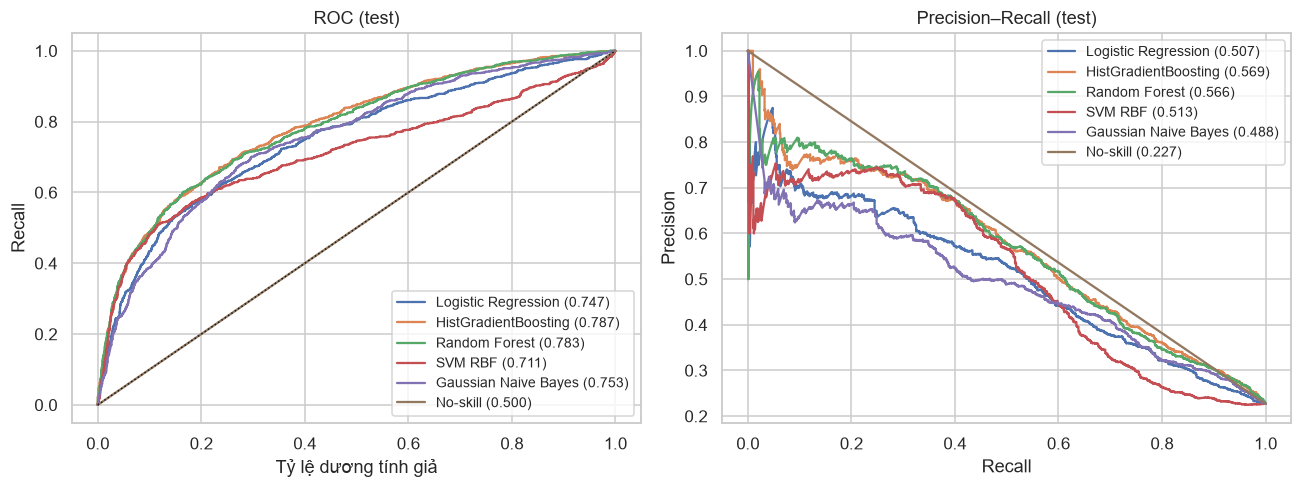

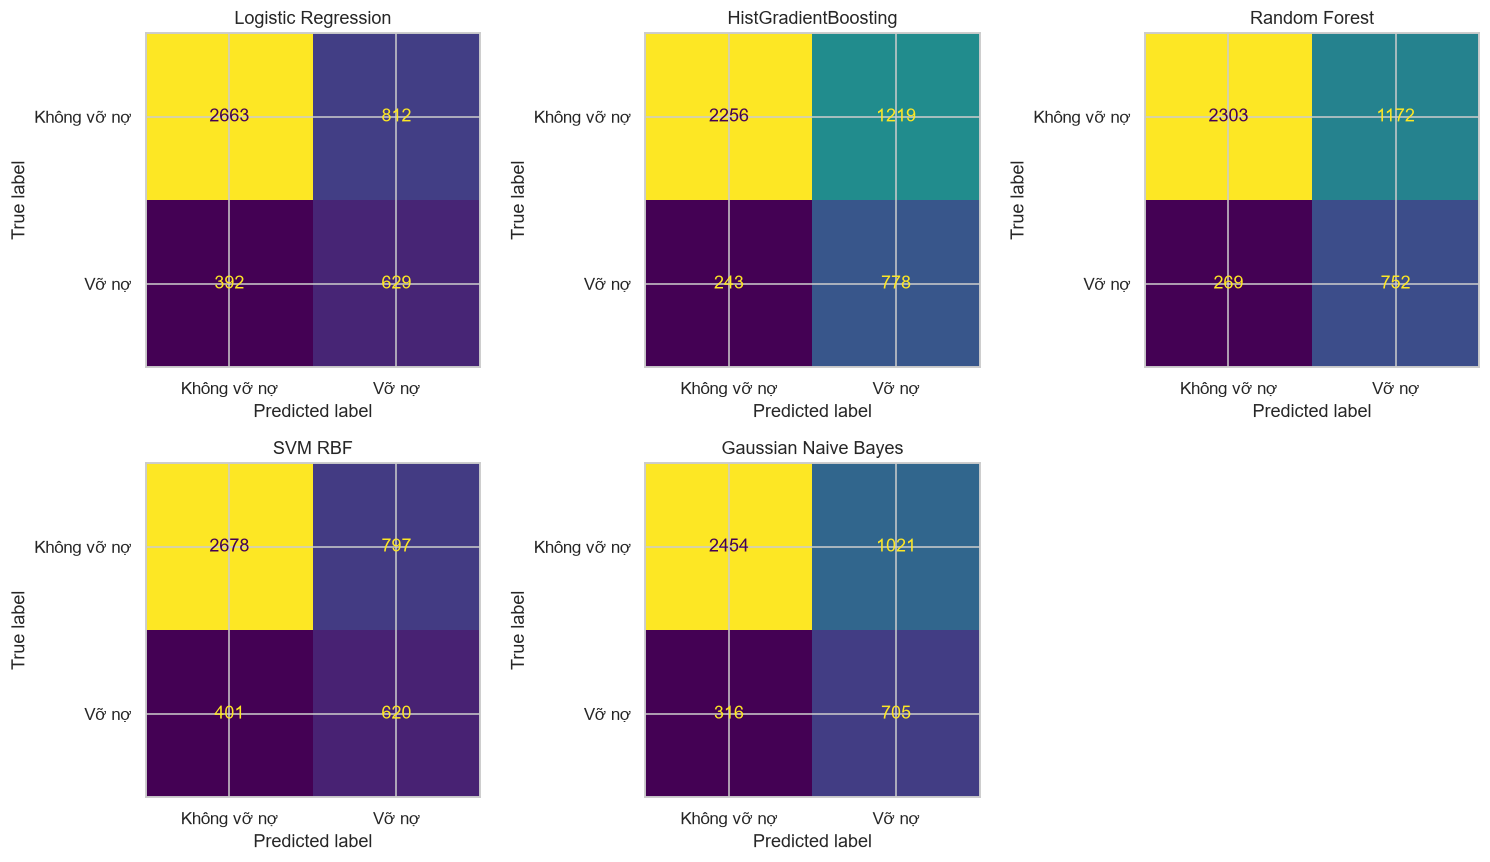

In [38]:
plot_curves()

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, name in zip(axes.flat, [n for n in results if n != DUMMY]):
    r = results[name]
    ConfusionMatrixDisplay.from_predictions(y_eval["test"], r["test"] >= r["threshold"], ax=ax,
                                            display_labels=["Không vỡ nợ", "Vỡ nợ"], colorbar=False)
    ax.set_title(name)
axes.flat[-1].set_visible(False)
plt.tight_layout()
plt.show()

## 30. Phân tích lỗi của mô hình được chọn

Bảng đầu đánh giá mô hình được chọn trên từng nhóm khách của test; PR-AUC của mỗi nhóm cần đối
chiếu với tỷ lệ vỡ nợ của chính nhóm đó. Bảng sau so đặc điểm trung bình của bốn nhóm TP / FN /
FP / TN. Nhóm nhỏ có độ bất định lớn; các bảng chỉ mô tả, không phải kết luận nhân quả hay về
tính công bằng.

In [39]:
display(slice_report(chosen).round(4))
display(error_profile(chosen).round(4))

Số KH  Tỷ lệ vỡ nợ  PR-AUC  Recall  Precision  \
Lát cắt   Nhóm                                                      
PAY_0     −2 / −1    1274       0.1656  0.3248  0.6019     0.2725   
          0          2183       0.1287  0.2209  0.4448     0.2244   
          1           544       0.3290  0.4595  0.9832     0.3674   
          ≥ 2         495       0.7071  0.7771  1.0000     0.7071   
Hạn mức   ≤ 50k      1149       0.3055  0.6030  0.8917     0.3826   
          50–100k     721       0.2705  0.5854  0.7487     0.4534   
          100–180k    920       0.2109  0.5660  0.7216     0.3733   
          180–270k    814       0.1757  0.5302  0.6853     0.3726   
          > 270k      892       0.1547  0.5033  0.5870     0.3699   
Tuổi      21–29      1446       0.2358  0.5716  0.7830     0.3881   
          30–39      1673       0.2020  0.5152  0.7189     0.3727   
          40–49       960       0.2438  0.6158  0.7564     0.4116   
          ≥ 50        417       0.2590  0.6433  0.8426     0.4009   
Giới tính Nam        1770       0.2520  0.6019  0.7825     0.4145   
          Nữ         2726       0.2109  0.5426  0.7461     0.3714   

                    Chi phí / KH  
Lát cắt   Nhóm                    
PAY_0     −2 / −1         0.5958  
          0               0.5552  
          1               0.5846  
          ≥ 2             0.2929  
Hạn mức   ≤ 50k           0.6049  
          50–100k         0.5839  
          100–180k        0.5489  
          180–270k        0.4791  
          > 270k          0.4742  
Tuổi      21–29           0.5470  
          30–39           0.5284  
          40–49           0.5604  
          ≥ 50            0.5300  
Giới tính Nam             0.5525  
          Nữ              0.5341

,Số KH,LIMIT_BAL,AGE,PAY_0,late_month_count,max_delay,utilization_sep,zero_payment_count,Xác suất
TP,778,119614.3959,36.1144,1.0360,2.6710,1.8856,0.5110,2.0424,0.4970
FN,243,186831.2757,35.5473,-0.4691,0.0658,0.1029,0.4619,0.7407,0.1119
FP,1219,124191.9606,35.6440,0.1534,1.4061,1.2477,0.4113,2.1017,0.3222
TN,2256,205394.5035,35.4632,-0.4091,0.0536,0.0762,0.3871,0.5776,0.0949


## 31. Tổng kết

- **HistGradientBoosting** có PR-AUC CV cao nhất và hơn Logistic Regression nhiều hơn một độ lệch
  chuẩn nên được chọn. Trên test, so với mô hình cơ sở, mô hình này phát hiện thêm khoảng 150 khách
  vỡ nợ, đổi lại nhắc nhầm thêm khoảng 400 khách; vì bỏ sót đắt gấp 5 lần nên tổng chi phí vẫn giảm.
  Hai khác biệt về PR-AUC và chi phí đều có khoảng tin cậy không chứa 0.
- **Random Forest** gần bằng HGB; **SVM RBF** và **Gaussian Naive Bayes** kém hơn và chỉ nhỉnh
  hơn hoặc kém Logistic Regression. Accuracy giảm khi chi phí giảm, đúng là lý do không dùng
  Accuracy để chọn mô hình.
- **Hạn chế:** Logistic Regression dùng 23 đặc trưng gốc, các mô hình còn lại dùng thêm sáu đặc
  trưng hành vi, nên mức cải thiện gồm cả đóng góp của đặc trưng (chưa làm ablation). Tỷ lệ chi phí
  5:1 là giả định; xác suất chưa được kiểm tra calibration; dữ liệu Đài Loan năm 2005 chưa được
  đánh giá theo thời gian. Bảng so sánh năm mô hình mang tính khám phá vì cùng tập test đã được dùng
  trong quá trình dự án.

Mã nguồn tương ứng trong repo: `src/modeling.py` (LR, HGB) và `src/modeling_team.py` (RF, SVM, NB);
chạy `python -m src.modeling_team` để ghi các bảng `reports/tables/12_*.csv` dùng trong báo cáo.